# Nigeria Inflation Forecast

Nigerian households and small businesses set prices, salaries and savings without knowing where inflation is heading.
Headline inflation peaked above 30% in 2024, the CPI was rebased in January 2025, and inflation has since fallen to about 14.6% (September 2026).
**Will that decline continue, level off, or reverse?**

In this notebook we pull Nigeria's monthly inflation, crude oil prices and the naira/dollar exchange rate from the Central Bank of Nigeria (CBN),
explore them, compare forecasting models against a naive baseline, and forecast the next 6–12 months with an uncertainty range.

## 1. Setup

We load the libraries we need:

- `pandas`: tables (DataFrames) and time-series tools
- `requests`: downloads data from a web address (URL)
- `matplotlib.pyplot`: draws charts
- `Path`: builds file paths that work on Windows, Mac and Linux

We also fix one colour per series, so headline is always blue, food always orange and core always green in every chart.

In [41]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

# Chart colours used throughout the notebook (one fixed colour per series)
HEADLINE_COLOUR = "#2a78d6"  # blue
FOOD_COLOUR = "#eb6834"      # orange
CORE_COLOUR = "#1baf7a"      # green
FX_COLOUR = "#6250d6"        # violet, for the naira/dollar rate
CRUDE_COLOUR = "#eda100"     # yellow, for crude oil
REBASE_COLOUR = "#52514e"    # dark grey, for the January 2025 rebasing marker

## 2. Data pull

**Question:** Can we pull Nigeria's monthly inflation, crude oil price and naira/dollar rate straight from the CBN and combine them into one monthly table?

The data pages on cbn.gov.ng load their numbers from hidden **JSON feeds**. JSON is a text format for data: here, each feed is a long list of
records, and each record (one month or one day) becomes a row in our table.

These feeds are **undocumented**, so the CBN could change or remove them without warning. That's why we always save a CSV copy after a
successful pull, and fall back to that copy if the download fails.

In [42]:
# The three hidden JSON feeds behind cbn.gov.ng data pages (undocumented, so they may change)
BASE_URL = "https://www.cbn.gov.ng/api/"
INFLATION_ENDPOINT = "GetAllInflationRates"
CRUDE_ENDPOINT = "GetAllDailyCrude"
FX_ENDPOINT = "GetAllExchangeRates"

# Some servers refuse requests that don't look like they come from a web browser,
# so we send the same "User-Agent" label a normal browser would
HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/130.0 Safari/537.36"
}

# Where we keep our saved copy of the cleaned monthly table
CSV_PATH = Path("data") / "nigeria_macro.csv"

### 2.1 Download the three feeds

`requests.get()` asks the server for a URL and returns a **response**. Every response has a **status code**: `200` means OK,
`403` means "forbidden" (blocked), `404` means "not found". `raise_for_status()` turns any bad status code into an error, so a
failed download can't slip through silently. `timeout=60` means: give up after 60 seconds instead of waiting forever.

We wrap the downloads in `try` / `except`. If **anything** goes wrong (no internet, the server blocks us, the reply isn't valid JSON),
we print the problem and set `live_data = False`. Later cells then load the saved CSV instead of crashing.

In [43]:
def fetch_json(endpoint):
    # Download one CBN feed and return it as a list of records (dictionaries)
    url = BASE_URL + endpoint
    response = requests.get(url, headers=HEADERS, timeout=60)
    response.raise_for_status()  # stop with an error if the server says no (e.g. 403 or 404)
    records = response.json()
    print(f"{endpoint}: {len(records):,} records")
    return records

In [44]:
try:
    inflation_raw = fetch_json(INFLATION_ENDPOINT)
    crude_raw = fetch_json(CRUDE_ENDPOINT)
    fx_raw = fetch_json(FX_ENDPOINT)
    live_data = True
except (requests.RequestException, ValueError) as error:
    # RequestException = network problem or bad status code; ValueError = the reply wasn't valid JSON
    print("Could not get live data from the CBN API:", error)
    print("We'll load the saved CSV copy instead.")
    live_data = False

GetAllInflationRates: 285 records
GetAllDailyCrude: 3,978 records
GetAllExchangeRates: 62,450 records


Let's look at one raw record from each feed before cleaning anything.

*Cells that start with `if live_data:` only do something when the download worked.*

In [45]:
if live_data:
    print(inflation_raw[0])
    print(crude_raw[0])
    print(fx_raw[0])

{'id': 298, 'tyear': 2026, 'tmonth': 9, 'period': 'September 2026', 'allItemsYearOn': '14.63', 'allItemsAverage': '15.80', 'foodYearOn': '19.59', 'foodAverage': '15.72', 'allItemsLessFrmProdYearOn': '12.78', 'allItemsLessFrmProdAverage': '15.91', 'allItemsLessFrmProdAndEnergyYearOn': '12.95', 'allItemsLessFrmProdAndEnergyAvg': '16.54'}
{'id': 4998, 'postDate': '22/10/2026', 'crudeOilPrice': '123.9700'}
{'id': 65222, 'currency': 'CFA', 'ratedate': '2026-10-22', 'buyingrate': '2.2650', 'centralrate': '2.2750', 'sellingrate': '2.2850'}


**Finding:** All three feeds downloaded (285 monthly inflation records, about 4,000 daily crude prices and about 62,000 daily exchange rates).
Three things to fix while cleaning:
1. **Every number is text.** Notice the quotes in `'allItemsYearOn': '14.63'`. We can't do maths on text, so we convert with `pd.to_numeric`.
2. **Newest first.** Time series should run oldest → newest.
3. **Different date styles.** Inflation has separate year and month numbers, crude uses `dd/mm/yyyy`, and exchange rates use `yyyy-mm-dd`.

### 2.2 Clean the inflation feed

We keep three **year-on-year** rates. "Year-on-year" means: how much higher prices are than in the same month last year.

| Feed column | Our name | Meaning |
|---|---|---|
| `allItemsYearOn` | `Headline` | All goods and services |
| `foodYearOn` | `Food` | Food only |
| `allItemsLessFrmProdAndEnergyYearOn` | `Core` | Everything except farm produce and energy, the less volatile part |

We build a proper date from `tyear` and `tmonth`, using **day 1** of each month. Every series in this project will use
month-start dates, so they line up exactly when we combine them.

In [46]:
def clean_inflation(records):
    # Turn the raw inflation records into a monthly table, oldest month first
    df = pd.DataFrame(records)

    # Build a real date from the year and month columns (day 1 = "month start")
    df["Date"] = pd.to_datetime({"year": df["tyear"], "month": df["tmonth"], "day": 1})

    # Keep only the year-on-year rates we need, with short names
    df = df.rename(columns={
        "allItemsYearOn": "Headline",
        "foodYearOn": "Food",
        "allItemsLessFrmProdAndEnergyYearOn": "Core",
    })
    df = df[["Date", "Headline", "Food", "Core"]]

    # Convert text like "14.63" to numbers; anything that isn't a number becomes NaN (blank),
    # which our checks in section 2.6 will catch
    for column in ["Headline", "Food", "Core"]:
        df[column] = pd.to_numeric(df[column], errors="coerce")

    # The feed is newest-first; time series should run oldest-first
    df = df.set_index("Date").sort_index()
    return df

In [47]:
if live_data:
    inflation = clean_inflation(inflation_raw)
    print(inflation.dtypes)
    display(inflation.tail())

Headline    float64
Food        float64
Core        float64
dtype: object


,Headline,Food,Core
Date,,,
2026-05-01,15.93,16.96,16.82
2026-06-01,15.91,17.52,15.92
2026-07-01,15.43,20.31,14.97
2026-08-01,15.39,19.57,13.29
2026-09-01,14.63,19.59,12.95


**Finding:** The inflation table has 285 months, from January 2003 to September 2026, with no gaps. The three columns are now
`float64` (decimal numbers) instead of text. In September 2026, headline inflation was **14.63%**, food **19.59%** and core **12.95%**.

### 2.3 Clean the crude oil feed

This is the daily price of **Bonny Light**, Nigeria's main export crude, in US dollars per barrel. Two techniques are new here:

- **An explicit date format.** A date like `03/04/2020` could be 3 April or 4 March. We tell pandas the exact format (`%d/%m/%Y`
  = day/month/year) so it can't guess wrong.
- **Resampling.** Inflation is monthly but crude is daily. `resample("MS").mean()` groups all the days in each month and takes the
  average. `"MS"` means "label each group by its **M**onth **S**tart", so January 2020's average gets the date 2020-01-01, the same
  as January 2020's inflation.

In [48]:
def clean_crude(records):
    # Turn daily crude oil prices into monthly average prices (US$ per barrel)
    df = pd.DataFrame(records)

    # Dates look like "22/10/2026" (day/month/year), so give pandas the exact format
    df["Date"] = pd.to_datetime(df["postDate"], format="%d/%m/%Y")
    df["Crude_USD"] = pd.to_numeric(df["crudeOilPrice"], errors="coerce")

    # Average all the days in each month (this also absorbs the few duplicate days in the feed)
    monthly = df.set_index("Date")["Crude_USD"].resample("MS").mean()
    return monthly.round(2)

In [49]:
if live_data:
    crude_monthly = clean_crude(crude_raw)
    print("First month:", crude_monthly.index.min().date(), "| Last month:", crude_monthly.index.max().date())

    # resample() creates a row for every month, so a month with no daily prices shows up as NaN
    empty_months = crude_monthly[crude_monthly.isna()].index.strftime("%Y-%m").tolist()
    print("Months with no crude prices:", empty_months)
    display(crude_monthly["2020-01":"2020-06"])

First month: 2009-10-01 | Last month: 2026-10-01
Months with no crude prices: ['2019-06', '2019-07']


Date
2020-01-01    66.44
2020-02-01    58.46
2020-03-01    33.02
2020-04-01    14.28
2020-05-01    27.62
2020-06-01    40.23
Freq: MS, Name: Crude_USD, dtype: float64

**Finding:** Crude prices start in **October 2009**, so the combined table will have no crude price for 2003 to September 2009.
**June and July 2019 are missing** from the CBN feed entirely. We'll decide how to handle these gaps in Phase 3.
The April 2020 average is very low, with a few days at $7–10 a barrel. That's not an error: it's the COVID-19 oil price
crash, when lockdowns cut global oil demand.

### 2.4 Clean the exchange-rate feed

This feed has daily official rates for **every** currency, and we only want the US dollar. CLAUDE.md warns that the currency names are messy,
so let's **look before we filter**. `repr()` prints each name with quote marks around it, which makes hidden spaces and tabs (`\t`) visible.

In [50]:
if live_data:
    fx = pd.DataFrame(fx_raw)
    # repr() shows hidden characters, e.g. 'US DOLLAR ' with a trailing space
    for name in sorted(fx["currency"].unique()):
        print(repr(name))

'CFA'
'CFA '
'DANISH KRONA'
'DANISH KRONER'
'EURO'
'EURO\t'
'EURO '
'JAPANESE YEN'
'NAIRA'
'POESO'
'POUND STERLING'
'POUNDS STERLING'
'RIYAL'
'RIYAL '
'SDR'
'SDR\t'
'SDR '
'SOUTH AFRICAN RAND'
'SWISS FRANC'
'SWISS FRANC\t'
'UAE DIRHAM'
'US DOLLAR'
'US DOLLAR '
'WAUA'
'WAUA '
'YEN'
'YEN '
'YUAN/RENMINBI'


**Finding:** The names are messy. There's `'US DOLLAR'` *and* `'US DOLLAR '` (trailing space), `'EURO\t'` (a hidden tab),
and spelling variants like `'DANISH KRONA'` / `'DANISH KRONER'` and `'POUND STERLING'` / `'POUNDS STERLING'`.
If we filtered for `"US DOLLAR"` without cleaning, we'd silently lose the rows with a space. `.str.strip()` removes spaces and tabs
from both ends of each name, which is all the US dollar needs.

Each day has three rates: **buying**, **selling**, and **central** (the official midpoint between them). We use the **central rate**,
in naira per US dollar, then average each month just like crude.

In [51]:
def clean_usd_ngn(records):
    # Pick out the US dollar rows and turn daily rates into monthly averages (naira per dollar)
    df = pd.DataFrame(records)

    # Remove hidden spaces/tabs so "US DOLLAR " and "US DOLLAR" count as the same currency
    df["currency"] = df["currency"].str.strip()
    usd = df[df["currency"] == "US DOLLAR"].copy()

    usd["Date"] = pd.to_datetime(usd["ratedate"])  # already in yyyy-mm-dd format
    usd["USD_NGN"] = pd.to_numeric(usd["centralrate"], errors="coerce")

    monthly = usd.set_index("Date")["USD_NGN"].resample("MS").mean()
    return monthly.round(2)

In [52]:
if live_data:
    usd_ngn_monthly = clean_usd_ngn(fx_raw)
    print("First month:", usd_ngn_monthly.index.min().date(), "| Last month:", usd_ngn_monthly.index.max().date())
    print("Months with no rate:", usd_ngn_monthly.isna().sum())
    # Around the June 2023 float of the naira
    display(usd_ngn_monthly["2023-03":"2023-09"])

First month: 2001-12-01 | Last month: 2026-10-01
Months with no rate: 0


Date
2023-03-01    460.43
2023-04-01    460.42
2023-05-01    460.70
2023-06-01    607.75
2023-07-01    769.82
2023-08-01    761.62
2023-09-01    761.33
Freq: MS, Name: USD_NGN, dtype: float64

**Finding:** The US dollar rate runs from December 2001 with no missing months. The June 2023 float is easy to see: about
**₦461** per dollar in May 2023, **₦608** in June and **₦770** in July. This is a jump of roughly two-thirds in two months. Jumps like this
are **policy decisions**, not random noise, and we'll keep that in mind when modelling.

### 2.5 Combine into one monthly table, save it, or fall back to the saved copy

We use the inflation table as the "spine" and **join** the crude and FX columns onto it, matching rows by `Date`.
`join` keeps only the months in the inflation table, so months the other feeds have but inflation doesn't
(e.g. October 2026, which is only partly over) drop out.

If the download worked, we save the result to `data/nigeria_macro.csv`. If it didn't, we load the last saved copy.

In [53]:
if live_data:
    inflation = clean_inflation(inflation_raw)
    crude_monthly = clean_crude(crude_raw)
    usd_ngn_monthly = clean_usd_ngn(fx_raw)

    macro = inflation.join(crude_monthly).join(usd_ngn_monthly)

    CSV_PATH.parent.mkdir(exist_ok=True)  # make sure the data/ folder exists
    macro.to_csv(CSV_PATH)
    print("Live data pulled and saved to", CSV_PATH)
else:
    macro = pd.read_csv(CSV_PATH, index_col="Date", parse_dates=True)
    print("Loaded saved copy from", CSV_PATH)

Live data pulled and saved to data\nigeria_macro.csv


### 2.6 Check the combined table

After every merge we check four things: the **date range**, **missing months**, **duplicate months** and **blank values**.
A merge can silently create any of these problems.

In [54]:
print("Rows, columns:", macro.shape)
print("From", macro.index.min().date(), "to", macro.index.max().date())

# Every month between the first and last date should appear exactly once
all_months = pd.date_range(macro.index.min(), macro.index.max(), freq="MS")
print("Missing months:", len(all_months.difference(macro.index)))
print("Duplicate months:", macro.index.duplicated().sum())

# Count blank (NaN) values in each column
print("\nBlank values per column:")
print(macro.isna().sum())

Rows, columns: (285, 5)
From 2003-01-01 to 2026-09-01
Missing months: 0
Duplicate months: 0

Blank values per column:
Headline      0
Food          0
Core          0
Crude_USD    83
USD_NGN       0
dtype: int64


In [55]:
display(macro.head())
display(macro.tail())

,Headline,Food,Core,Crude_USD,USD_NGN
Date,,,,,
2003-01-01,10.6,7.5,13.6,NaN,126.59
2003-02-01,7.3,3.5,12.1,NaN,127.00
2003-03-01,5.9,0.1,13.9,NaN,126.86
2003-04-01,8.3,3.3,17.6,NaN,126.98
2003-05-01,8.7,3.3,15.5,NaN,127.17


,Headline,Food,Core,Crude_USD,USD_NGN
Date,,,,,
2026-05-01,15.93,16.96,16.82,112.04,1369.49
2026-06-01,15.91,17.52,15.92,87.70,1366.49
2026-07-01,15.43,20.31,14.97,84.81,1372.75
2026-08-01,15.39,19.57,13.29,94.64,1352.47
2026-09-01,14.63,19.59,12.95,117.10,1326.81


**Finding:** We now have one clean monthly table: **285 months** (January 2003 to September 2026) with columns `Headline`, `Food`, `Core`,
`Crude_USD` and `USD_NGN`, saved to `data/nigeria_macro.csv`. There are no missing or duplicate months. The only blanks are in
`Crude_USD`: 81 months before the crude feed starts (January 2003 to September 2009) plus the June and July 2019 gap, so **83** in total.

Still to come in Phase 3 (data quality): add the `Rebased` marker for the January 2025 CPI rebasing, decide what to do with the crude gaps,
and spot-check the CBN numbers against NBS press releases.

## 3. Data quality

**Question:** Can we trust this table enough to build forecasts on it?

A model can't tell a real price shock from a data error, so we check the data *before* modelling:

1. Are the types and value ranges sensible?
2. Are there any copy errors (a month that exactly repeats the one before)?
3. Does the CBN feed agree with the official NBS press releases?
4. How do we fill the gaps?
5. How do we handle the January 2025 CPI rebasing?

### 3.1 Types and value ranges

`dtypes` shows each column's type, and `describe()` gives a quick summary of each column: count, average (`mean`),
spread (`std`), smallest (`min`), largest (`max`) and the quarter points in between.

In [56]:
print(macro.dtypes)
macro.describe().round(2)

Headline     float64
Food         float64
Core         float64
Crude_USD    float64
USD_NGN      float64
dtype: object


,Headline,Food,Core,Crude_USD,USD_NGN
count,285.00,285.00,285.00,202.00,285.00
mean,14.52,15.55,12.93,79.98,374.15
std,6.54,8.26,6.28,24.97,418.06
min,3.00,-3.70,-6.50,14.28,113.70
25%,10.20,10.10,9.40,63.66,142.26
50%,12.90,14.50,12.30,77.25,167.50
75%,17.26,19.27,14.97,103.63,379.50
max,34.80,40.87,29.28,129.90,1670.28


In [57]:
# Months where food or core inflation was negative (prices lower than a year before)
macro[(macro["Food"] < 0) | (macro["Core"] < 0)]

,Headline,Food,Core,Crude_USD,USD_NGN
Date,,,,,
2004-12-01,10.0,12.1,-1.8,NaN,132.36
2006-07-01,3.0,-3.7,15.2,NaN,126.62
2006-08-01,3.7,-2.3,11.9,NaN,126.56
2007-01-01,8.0,-0.1,13.2,NaN,126.51
2007-06-01,6.4,3.2,-0.3,NaN,125.69
2007-07-01,4.8,1.1,-0.4,NaN,125.42
2007-08-01,4.2,-1.2,5.6,NaN,122.64
2007-09-01,4.1,-0.8,3.7,NaN,124.12
2007-10-01,4.6,-0.1,-0.9,NaN,122.68


**Finding:** All five columns are numbers (`float64`). Headline inflation ranges from **3.0%** to **34.8%**, and the naira went from
about ₦114 to over ₦1,600 per dollar. Those are big ranges but real ones. The only surprise is **negative food and core rates** in 2004–2008
(core fell as low as −6.5% in December 2007). The early years of the series (2003–2008) jump around a lot from month to month.
That's how the published series looks, not a mistake in our download, but it means those years are less reliable for modelling.

### 3.2 Copy errors: does any month repeat the month before?

Inflation rates are published to two decimal places, so it would be a big coincidence for headline, food **and** core all to be exactly
the same as the previous month. `diff()` subtracts the previous month from each month. If all three differences are 0, the row is a repeat.

In [58]:
inflation_columns = ["Headline", "Food", "Core"]
change_from_last_month = macro[inflation_columns].diff()

# A repeat = all three columns unchanged (the first month has nothing to compare with, so skip it)
is_repeat = (change_from_last_month == 0).all(axis=1)
macro.loc["2025-04":"2025-07", inflation_columns].assign(repeat_of_last_month=is_repeat)

,Headline,Food,Core,repeat_of_last_month
Date,,,,
2025-04-01,26.82,24.68,26.05,False
2025-05-01,26.06,24.55,24.92,False
2025-06-01,26.06,24.55,24.92,True
2025-07-01,24.94,26.20,23.95,False


**Finding:** Only one month in 23 years is an exact repeat: **June 2025 is identical to May 2025** (26.06 / 24.55 / 24.92).
The NBS press releases for those two months gave different numbers (22.97% in May and 22.22% in June), so June in the CBN feed is almost
certainly a copy error. We'll fix it in 3.4.

### 3.3 Spot-check: CBN feed vs NBS press releases

The **NBS** (National Bureau of Statistics) calculates Nigeria's inflation and announces it in a monthly press release. The CBN feed is
a copy of those numbers, so they should match. CLAUDE.md flagged one month that doesn't: January 2025 is **27.61%** in the feed but
**24.48%** in the NBS announcement. Let's check more months.

Below are the headline rates **as first published** by NBS, taken from news reports of each press release. For two months, a later NBS
release quotes a **revised** figure for the same month, so we record that too.

Sources: [Dec 2024](https://proshare.co/articles/nigerias-inflation-rate-rises-to-34.80-in-december-2024-says-nbs),
[Jan 2025](https://thecable.ng/breaking-nigerias-inflation-rate-drops-from-34-8-to-24-48-after-rebasing-cpi),
[May 2025](https://gazettengr.com/nigerias-inflation-rate-dropped-to-22-97-in-may-nbs/),
[Jun 2025](https://gazettengr.com/nigerias-inflation-rate-drops-to-22-22-in-june-says-nbs/),
[Jul 2025](https://guardian.ng/news/headline-inflation-slows-to-21-88-in-july-2/),
[Aug 2025](https://allafrica.com/stories/202509160075.html),
[Sep 2025](https://nannews.ng/nigerias-inflation-rate-eases-to-18-02-in-september-nbs/),
[Oct and Nov 2025](https://von.gov.ng/?p=503754),
[Dec 2025, revised Nov](https://von.gov.ng/nigerias-inflation-rate-eases-to-15-15-percent-nbs/),
[Sep 2026, revised Sep 2025](https://businessday.ng/uncategorized/article/nigerias-inflation-drops-to-14-63-as-food-prices-fall-in-september/),
[the January 2026 correction](https://stopsandgaps.substack.com/p/the-nbs-backtracks).

In [59]:
# Headline inflation (%) as published by NBS; None = no revised figure found
nbs_releases = pd.DataFrame({
    "Date": ["2024-12-01", "2025-01-01", "2025-05-01", "2025-06-01", "2025-07-01", "2025-08-01",
             "2025-09-01", "2025-10-01", "2025-11-01", "2025-12-01", "2026-09-01"],
    "NBS_first_release": [34.80, 24.48, 22.97, 22.22, 21.88, 20.12, 18.02, 16.05, 14.45, 15.15, 14.63],
    "NBS_revised": [None, None, None, None, None, None, 20.98, None, 17.33, None, None],
})
nbs_releases["Date"] = pd.to_datetime(nbs_releases["Date"])
spot_check = nbs_releases.set_index("Date")

# Put the CBN feed's number next to each NBS number and measure the gap
spot_check["CBN_feed"] = macro.loc[spot_check.index, "Headline"]
spot_check["CBN_minus_first_release"] = (spot_check["CBN_feed"] - spot_check["NBS_first_release"]).round(2)
spot_check

,NBS_first_release,NBS_revised,CBN_feed,CBN_minus_first_release
Date,,,,
2024-12-01,34.80,NaN,34.80,0.00
2025-01-01,24.48,NaN,27.61,3.13
2025-05-01,22.97,NaN,26.06,3.09
2025-06-01,22.22,NaN,26.06,3.84
2025-07-01,21.88,NaN,24.94,3.06
2025-08-01,20.12,NaN,23.14,3.02
2025-09-01,18.02,20.98,20.98,2.96
2025-10-01,16.05,NaN,18.97,2.92
2025-11-01,14.45,17.33,17.33,2.88


**Finding:** There's a clear pattern:

- **December 2024 and earlier** (old CPI) match exactly.
- **January to November 2025:** the CBN feed is about **3 percentage points higher** than what NBS first announced
  (food and core too: January 2025 food is 29.63% in the feed vs 26.08% announced, and core is 25.27% vs 22.59%).
- **Where NBS later published a revised figure, it matches the CBN feed exactly** (September 2025: 20.98%, November 2025: 17.33%).
- **December 2025 onwards** match the first releases.

So the gap isn't a CBN mistake. In **January 2026, NBS corrected an error in its newly rebased CPI** and revised its 2025 figures upward,
and the CBN feed holds the **corrected** numbers. We'll keep the CBN series: it's the latest official version, and it's consistent from
month to month. But anyone comparing our charts with 2025 news headlines will see different numbers, so we'll explain this in the README.

The one exception is **June 2025**: the feed copies May's numbers, and we don't have the revised June figure, so we'll estimate it from its neighbours.

### 3.4 Filling the gaps: interpolation

We have three kinds of gaps:

| Gap | Cause | What we do |
|---|---|---|
| June 2025 inflation | Copy error in the feed | Blank it, then fill it in |
| June–July 2019 crude price | Missing from the CBN feed | Fill it in |
| Crude before October 2009 | The feed starts in 2009 | **Leave blank** |

**Interpolation** fills a gap by drawing a straight line between the known values on either side and reading off the missing points.
For one or two missing months in the *middle* of a series, that's a reasonable estimate.

`limit_area="inside"` tells pandas to fill **only** gaps that have real values on both sides. The six years of crude prices before
October 2009 have nothing before them, so filling them would mean inventing data. We leave them blank. Any model that uses crude oil will
simply start in October 2009.

In [60]:
# June 2025 is an exact copy of May 2025 in the feed: blank it out first...
macro.loc["2025-06-01", inflation_columns] = float("nan")

# ...then fill each gap with a straight line between its neighbours (only gaps with data on both sides)
macro[inflation_columns] = macro[inflation_columns].interpolate(limit_area="inside")
macro["Crude_USD"] = macro["Crude_USD"].interpolate(limit_area="inside")

display(macro.loc["2025-05":"2025-07", inflation_columns])
display(macro.loc["2019-05":"2019-08", ["Crude_USD"]])

,Headline,Food,Core
Date,,,
2025-05-01,26.06,24.550,24.920
2025-06-01,25.50,25.375,24.435
2025-07-01,24.94,26.200,23.950


,Crude_USD
Date,
2019-05-01,73.340000
2019-06-01,69.156667
2019-07-01,64.973333
2019-08-01,60.790000


**Finding:** June 2025 is now halfway between May and July (headline **25.50%**), instead of a copy of May. The June and July 2019 crude prices
now step down evenly from \$73.34 in May to \$60.79 in August. These are **estimates**, and we'll say so wherever it matters.

### 3.5 The January 2025 rebasing break

**What is rebasing?** The CPI (Consumer Price Index) tracks the cost of a fixed "basket" of goods and services that a typical household buys.
The cost in the **base year** is set to 100. In January 2025, NBS **rebased** the CPI:

- The base year moved from 2009 to **2024**.
- The basket was updated to match what people buy today. Food's share of the basket was cut to about 40%, from roughly half before.

The year-on-year rate for January 2025 compares January 2025 with January 2024, with both measured on the *new* basket. December 2024's
rate (34.80%) was measured on the *old*, food-heavy basket during a food price spike. So the drop from December to January is
**mostly a change in the measuring tape, not prices suddenly calming down**.

We record this with a **dummy variable**, a column that is just 0 or 1. `Rebased` is 0 before January 2025 and 1 from January 2025 onwards.
Later, a model can use it to learn "the level shifted here" instead of mistaking the drop for normal behaviour.

In [61]:
# 1 from January 2025 onwards (rebased CPI, 2024 = 100), 0 before
macro["Rebased"] = (macro.index >= "2025-01-01").astype(int)
macro.loc["2024-10":"2025-03"]

,Headline,Food,Core,Crude_USD,USD_NGN,Rebased
Date,,,,,,
2024-10-01,33.88,39.16,28.37,76.69,1640.66,0
2024-11-01,34.60,39.93,28.75,75.44,1670.28,0
2024-12-01,34.80,39.84,29.28,74.72,1553.25,0
2025-01-01,27.61,29.63,25.27,80.71,1535.44,1
2025-02-01,26.27,26.98,25.66,77.06,1500.47,1
2025-03-01,27.35,25.22,27.12,74.44,1525.87,1


In [62]:
# How unusual was the December 2024 -> January 2025 move? The 5 biggest one-month changes since 2003:
headline_change = macro["Headline"].diff()
headline_change.abs().sort_values(ascending=False).head(5).round(2)

Date
2005-07-01    7.50
2025-01-01    7.19
2003-09-01    6.00
2004-06-01    5.70
2005-10-01    5.70
Name: Headline, dtype: float64

Now let's draw it. We zoom in on 2022 onwards and mark the rebasing with a dashed line and light shading. **Every time chart in this
project will carry this marker.**

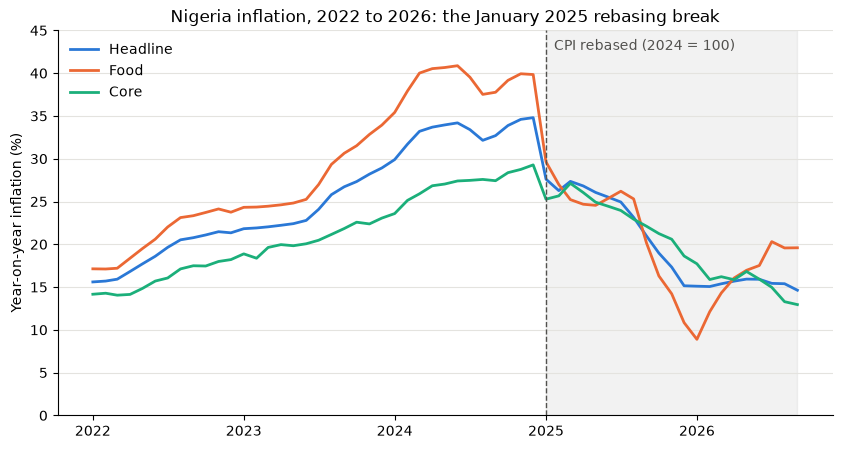

In [63]:
recent = macro.loc["2022-01":]
rebase_date = pd.Timestamp("2025-01-01")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(recent.index, recent["Headline"], color=HEADLINE_COLOUR, linewidth=2, label="Headline")
ax.plot(recent.index, recent["Food"], color=FOOD_COLOUR, linewidth=2, label="Food")
ax.plot(recent.index, recent["Core"], color=CORE_COLOUR, linewidth=2, label="Core")

# Rebasing marker: dashed line at January 2025, light shading for the rebased period
ax.axvline(rebase_date, color=REBASE_COLOUR, linestyle="--", linewidth=1)
ax.axvspan(rebase_date, recent.index.max(), color=REBASE_COLOUR, alpha=0.07)
ax.text(rebase_date, 44, "  CPI rebased (2024 = 100)", color=REBASE_COLOUR, va="top")

ax.set_ylim(0, 45)
ax.set_title("Nigeria inflation, 2022 to 2026: the January 2025 rebasing break")
ax.set_ylabel("Year-on-year inflation (%)")
ax.grid(axis="y", color="#e4e3df")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", frameon=False)

fig.savefig("images/rebasing_break.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Headline inflation fell **7.19 points in a single month**, from 34.80% (December 2024) to 27.61% (January 2025). Food fell
10.21 points. That's the second-largest one-month move in the whole series, after July 2005, and it happened exactly when the measuring method
changed. After the break, inflation keeps falling steadily through 2025 and levels off at about 15% in 2026, while food inflation turns back up
to about 20%.

**What this means for modelling:** a model trained on 2003–2024 has never seen the new CPI, and a model trained on everything would read the
January 2025 drop as a real shock. As CLAUDE.md asks, we'll try both: **(a) train on 2003–2024 only**, and **(b) train on all data with the
`Rebased` dummy**, and compare them.

### 3.6 Final check

Same checks as in 2.6, on the cleaned table.

In [64]:
print("Rows, columns:", macro.shape)
print("Duplicate months:", macro.index.duplicated().sum())
print("\nBlank values per column:")
print(macro.isna().sum())

Rows, columns: (285, 6)
Duplicate months: 0

Blank values per column:
Headline      0
Food          0
Core          0
Crude_USD    81
USD_NGN       0
Rebased       0
dtype: int64


**Finding:** The cleaned table has 285 months and six columns (`Headline`, `Food`, `Core`, `Crude_USD`, `USD_NGN`, `Rebased`), no duplicate months
and no blanks except the **81 months of crude price before October 2009**, which we left blank on purpose. The data is ready for exploring in
Phase 4.

*Note:* `data/nigeria_macro.csv` stays as the raw API snapshot. The cleaning in this section runs again every time the notebook runs, so
each fix is visible and easy to change.

## 4. Exploratory data analysis (EDA)

EDA means looking at the data with charts and simple statistics *before* modelling, to understand its patterns.
What we learn here decides which models make sense. We answer four questions:

1. How has inflation moved since 2003, and what happened around the big peaks?
2. How does food inflation compare with headline inflation?
3. Is there a repeating pattern within the year (seasonality)?
4. Do crude oil prices and the naira/dollar rate **lead** inflation, and by how many months?

First, a small helper function. CLAUDE.md asks for the rebasing to be marked on **every** time chart. Instead of copying the same three lines
into every chart, we write them once as a function and call it.

In [65]:
def mark_rebasing(ax, label=True):
    # Draw the January 2025 CPI rebasing marker on a chart: dashed line + light shading afterwards
    rebase_date = pd.Timestamp("2025-01-01")
    ax.axvline(rebase_date, color=REBASE_COLOUR, linestyle="--", linewidth=1)
    ax.axvspan(rebase_date, macro.index.max(), color=REBASE_COLOUR, alpha=0.07)
    if label:
        # Place the label just below the top of the chart
        top = ax.get_ylim()[1]
        ax.text(rebase_date, top, " CPI\n rebased", color=REBASE_COLOUR, va="top", fontsize=9)


def tidy_chart(ax):
    # Light horizontal grid lines, no box on the top and right
    ax.grid(axis="y", color="#e4e3df")
    ax.set_axisbelow(True)  # draw grid lines behind bars and lines
    ax.spines[["top", "right"]].set_visible(False)

### 4.1 Long-run history, 2003–2026

**Question:** How have headline, food and core inflation moved since 2003? What were the major peaks, and what happened around them?

We mark three events on the chart: the **2016 recession** (oil prices crashed and the naira was devalued in June 2016), the **COVID-19** shock
(March 2020), and the **fuel subsidy removal and naira float** (May–June 2023).

In [66]:
# Highest headline inflation in each period, to see the peaks
periods = {
    "2003-2008": ("2003", "2008"),
    "2016 recession": ("2016", "2018"),
    "COVID-19": ("2020", "2021"),
    "Subsidy removal + float": ("2023", "2024"),
}
for name, (start, end) in periods.items():
    headline = macro.loc[start:end, "Headline"]
    print(f"{name:25} peak {headline.max():5.2f}% in {headline.idxmax():%B %Y}")

2003-2008                 peak 28.20% in August 2005
2016 recession            peak 18.72% in January 2017
COVID-19                  peak 18.17% in March 2021
Subsidy removal + float   peak 34.80% in December 2024


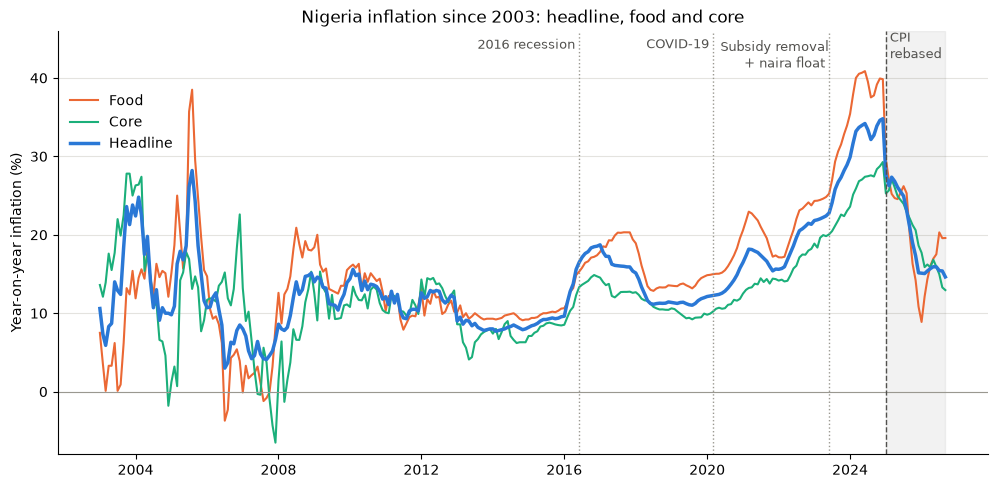

In [67]:
events = {
    "2016 recession": "2016-06-01",
    "COVID-19": "2020-03-01",
    "Subsidy removal\n+ naira float": "2023-06-01",
}

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(macro.index, macro["Food"], color=FOOD_COLOUR, linewidth=1.5, label="Food")
ax.plot(macro.index, macro["Core"], color=CORE_COLOUR, linewidth=1.5, label="Core")
ax.plot(macro.index, macro["Headline"], color=HEADLINE_COLOUR, linewidth=2.5, label="Headline")
ax.axhline(0, color="#9a9890", linewidth=0.8)

ax.set_ylim(-8, 46)
for label, date in events.items():
    ax.axvline(pd.Timestamp(date), color="#9a9890", linestyle=":", linewidth=1)
    ax.text(pd.Timestamp(date), 45, label + " ", ha="right", va="top", fontsize=9, color="#52514e")
mark_rebasing(ax)

ax.set_title("Nigeria inflation since 2003: headline, food and core")
ax.set_ylabel("Year-on-year inflation (%)")
tidy_chart(ax)
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.88), frameon=False)

fig.savefig("images/long_run_inflation.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Nigeria's inflation comes in **waves**, and each recent wave has peaked higher than the one before.

- **2003–2008** was very jumpy: a peak of 28.2% in August 2005, and even negative food and core rates in some months.
- **2010–2015** was the calmest stretch, with headline mostly between 8% and 13% and below 10% for much of 2013–2015.
- **2016 recession:** the oil price crash and the June 2016 devaluation pushed headline from 9.6% (January 2016) to a peak of **18.72%** (January 2017).
- **COVID-19:** inflation climbed again to **18.17%** in March 2021.
- **Subsidy removal and naira float (mid-2023):** headline rose from 22.4% in May 2023 to **34.80%** in December 2024, the highest in the whole series. Food peaked at 40.87% in June 2024.

After the January 2025 rebasing, inflation fell through 2025 and has stayed at about **15%** through 2026. Notice that the last three waves all began soon after a fall in the naira. We test that link in 4.4.

### 4.2 Food vs headline: the gap

**Question:** Does food inflation usually run above headline inflation, and by how much?

Food is the biggest part of what Nigerian households spend money on, so food inflation hits poorer families hardest. We calculate the
**gap** = food inflation − headline inflation. When the gap is positive, food prices are rising faster than prices in general.

In [68]:
food_gap = macro["Food"] - macro["Headline"]

print(f"Average gap, 2003-2024:      {food_gap[:'2024'].mean():5.2f} points")
print(f"Average gap, 2023-2024:      {food_gap['2023':'2024'].mean():5.2f} points")
print(f"Average gap, 2025 onwards:   {food_gap['2025':].mean():5.2f} points")
print(f"Share of months with food above headline: {(food_gap > 0).mean():.0%}")
print(f"Latest gap ({food_gap.index[-1]:%B %Y}): {food_gap.iloc[-1]:.2f} points")

Average gap, 2003-2024:       1.13 points
Average gap, 2023-2024:       4.58 points
Average gap, 2025 onwards:   -0.18 points
Share of months with food above headline: 71%
Latest gap (September 2026): 4.96 points


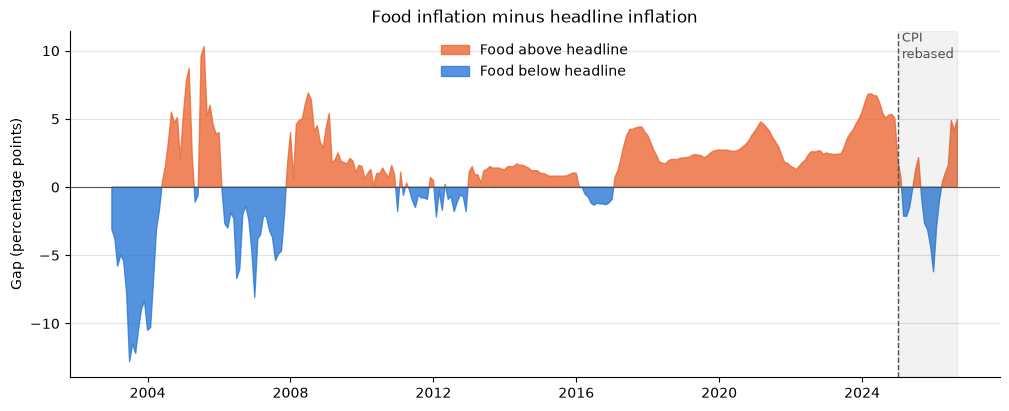

In [69]:
fig, ax = plt.subplots(figsize=(12, 4.5))

# Orange where food is above headline, blue where it's below
ax.fill_between(food_gap.index, food_gap, 0, where=food_gap >= 0, color=FOOD_COLOUR, alpha=0.8,
                interpolate=True, label="Food above headline")
ax.fill_between(food_gap.index, food_gap, 0, where=food_gap < 0, color=HEADLINE_COLOUR, alpha=0.8,
                interpolate=True, label="Food below headline")
ax.axhline(0, color="#52514e", linewidth=0.8)
mark_rebasing(ax)

ax.set_title("Food inflation minus headline inflation")
ax.set_ylabel("Gap (percentage points)")
tidy_chart(ax)
ax.legend(loc="upper center", frameon=False)

fig.savefig("images/food_headline_gap.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Food inflation is **usually higher** than headline: it was above headline in 71% of months, by **1.13 points** on average in 2003–2024. The gap widens in crises: about 4 points in 2017, about 5 in 2021, and **4.58 points on average in 2023–2024**.

After the rebasing, the pattern flipped for a while. Food fell *below* headline for most of 2025, with the gap reaching −6.21 points in January 2026, when food inflation was only 8.89%. But since early 2026, food inflation has **turned back up**. In September 2026 food was at 19.59% vs 14.63% for headline, a gap of **4.96 points**, as wide as during the 2023–2024 crisis. Food is the part of inflation to watch: if it keeps rising, the fall in headline inflation may not last.

### 4.3 Seasonality

**Question:** Is there a repeating pattern within the year, for example around Christmas or in the lean season before harvest?

**An important limit of our data first.** The feed gives **year-on-year** rates only: each month is compared with *the same month a year
earlier*. If prices always jump in December, December is compared with last December, which also jumped, so the seasonal effect
**mostly cancels out**. Year-on-year rates are "seasonally neutral" by design. (To measure true seasonality we'd need the month-on-month
rates or the CPI index itself, which NBS publishes but this feed doesn't include.)

So here is the check we *can* do: the **month-to-month change in the year-on-year rate**, averaged for each calendar month. If one calendar
month regularly pushes the rate up or down, its average will stand out from zero. We use 2003–2024 only, so the rebasing jump in January 2025
doesn't distort January's average.

In [70]:
change_in_rate = macro.loc[:"2024", "Headline"].diff()

# Group the changes by calendar month (1 = January ... 12 = December): average and typical spread
by_month = change_in_rate.groupby(change_in_rate.index.month).agg(["mean", "std"])
by_month.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
by_month.round(2).T

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
mean,0.02,0.10,0.16,-0.00,0.07,0.10,-0.09,0.16,0.15,0.32,-0.04,0.16
std,1.11,1.22,1.57,1.41,1.10,2.06,2.31,0.99,1.91,1.80,1.09,1.10


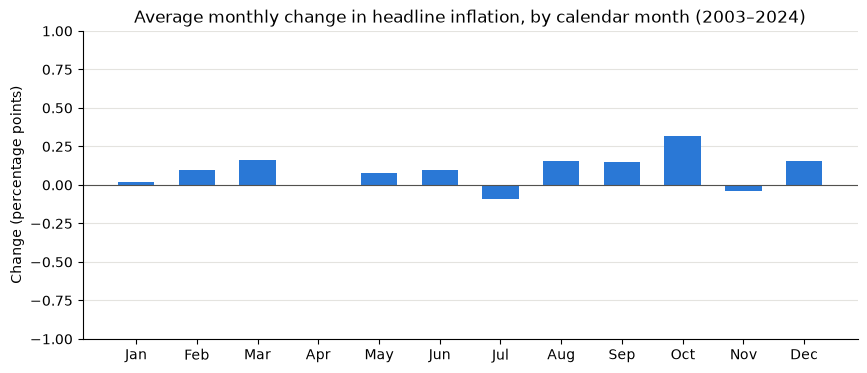

In [71]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_month.index, by_month["mean"], color=HEADLINE_COLOUR, width=0.6)
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_ylim(-1, 1)

ax.set_title("Average monthly change in headline inflation, by calendar month (2003–2024)")
ax.set_ylabel("Change (percentage points)")
tidy_chart(ax)

fig.savefig("images/seasonality.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** There's **no meaningful seasonal pattern** in the year-on-year rate. Every calendar month's average change is small, between −0.09 and +0.32 points. In comparison, the change in any single month typically varies by 1–2 points (the `std` row). October has the largest average (+0.32), but that's small next to the noise.

This is what we expected, because year-on-year rates cancel out most seasonal effects. **For modelling:** seasonal terms probably won't help when we forecast the year-on-year rate. In Phase 7 we'll test whether SARIMA's seasonal part helps, rather than assume it. Measuring the festive-season or lean-season pattern properly would need NBS's month-on-month rates, which this feed doesn't have.

### 4.4 Drivers: do crude oil and the naira lead inflation?

**Question:** Do changes in crude oil prices and the naira/dollar rate show up in inflation later, and at what lag (1, 3, 6 or 12 months)?

**Step 1: compare like with like.** Inflation is a year-on-year **% change**. Comparing it with the *level* of the exchange rate (₦1,500)
would be comparing a speed with a distance. So we turn the drivers into year-on-year % changes too: "how much more naira does a dollar cost
than a year ago?" and "how much more does a barrel of oil cost than a year ago?" `pct_change(12)` does exactly this: it compares each month
with 12 months earlier.

**Step 2: look at them together.** We can't put inflation and the naira on one chart with two different y-axes, because that makes it too
easy to see links that aren't there. Instead we stack three small charts that share the same time axis.

In [72]:
# Year-on-year % change of each driver
macro["USD_NGN_yoy"] = macro["USD_NGN"].pct_change(12) * 100
macro["Crude_yoy"] = macro["Crude_USD"].pct_change(12) * 100

# Around the June 2023 float: the naira's fall shows up as a big jump in USD_NGN_yoy
macro[["Headline", "USD_NGN_yoy", "Crude_yoy"]].loc["2023-04":"2023-09"].round(1)

,Headline,USD_NGN_yoy,Crude_yoy
Date,,,
2023-04-01,22.2,10.8,-18.7
2023-05-01,22.4,11.0,-34.4
2023-06-01,22.8,46.4,-40.5
2023-07-01,24.1,85.4,-31.8
2023-08-01,25.8,81.4,-16.0
2023-09-01,26.7,77.6,5.3


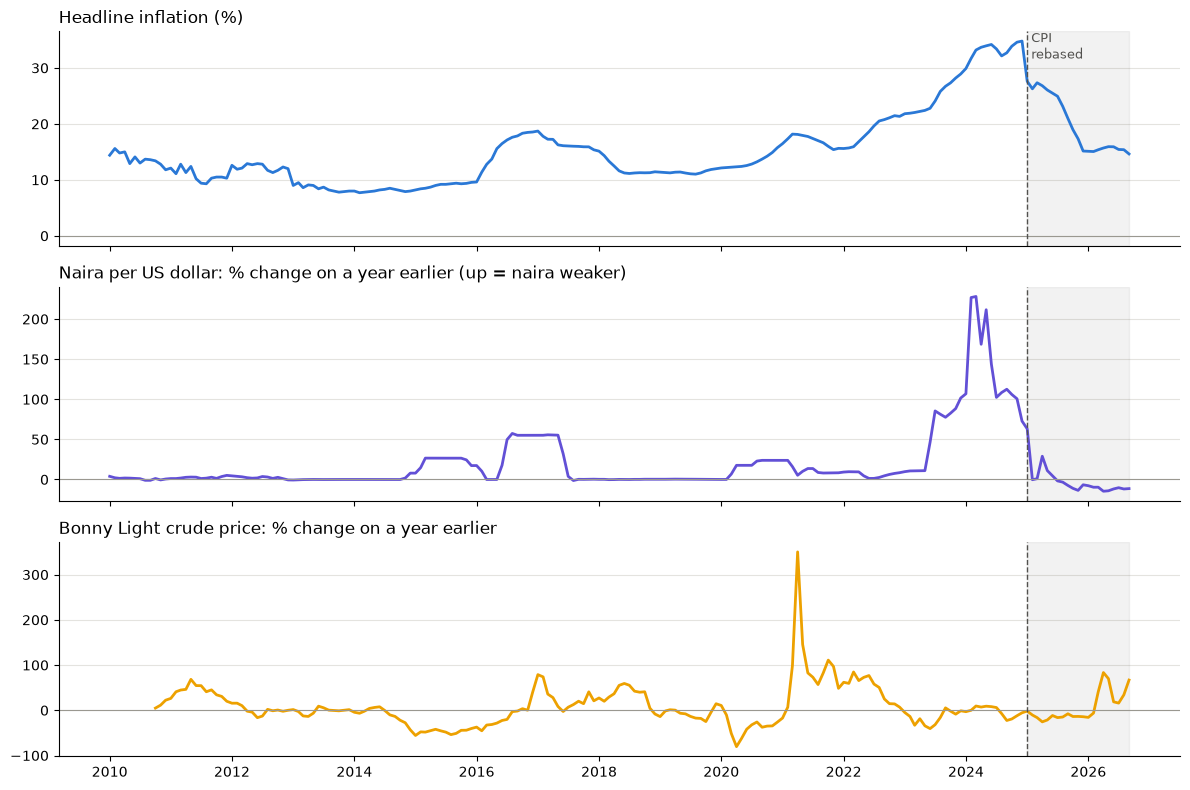

In [73]:
recent = macro.loc["2010":]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(recent.index, recent["Headline"], color=HEADLINE_COLOUR, linewidth=2)
axes[0].set_title("Headline inflation (%)", loc="left")

axes[1].plot(recent.index, recent["USD_NGN_yoy"], color=FX_COLOUR, linewidth=2)
axes[1].set_title("Naira per US dollar: % change on a year earlier (up = naira weaker)", loc="left")

axes[2].plot(recent.index, recent["Crude_yoy"], color=CRUDE_COLOUR, linewidth=2)
axes[2].set_title("Bonny Light crude price: % change on a year earlier", loc="left")

for ax in axes:
    ax.axhline(0, color="#9a9890", linewidth=0.8)
    tidy_chart(ax)
    mark_rebasing(ax, label=(ax is axes[0]))

fig.tight_layout()
fig.savefig("images/drivers.png", dpi=150, bbox_inches="tight")
plt.show()

**Step 3: measure the link at different lags.** A **lag** means shifting a series later in time. `shift(3)` moves the exchange rate 3 months
forward, so each month's inflation is lined up with the exchange rate from **3 months earlier**. If the naira's fall *leads* inflation,
the link should be stronger at some lag than at lag 0.

We measure the link with the **correlation** (`corr`), a number from −1 to +1:
- **+1:** the two always move up and down together
- **0:** no straight-line link
- **−1:** one goes up when the other goes down

We use data up to December 2024 only, so the rebasing break doesn't distort the result.

In [74]:
before_rebasing = macro.loc[:"2024"]
lags = [0, 1, 3, 6, 12]

rows = []
for lag in lags:
    rows.append({
        "Lag (months)": lag,
        "Naira fall vs Headline": before_rebasing["Headline"].corr(before_rebasing["USD_NGN_yoy"].shift(lag)),
        "Naira fall vs Food": before_rebasing["Food"].corr(before_rebasing["USD_NGN_yoy"].shift(lag)),
        "Naira fall vs Core": before_rebasing["Core"].corr(before_rebasing["USD_NGN_yoy"].shift(lag)),
        "Crude change vs Headline": before_rebasing["Headline"].corr(before_rebasing["Crude_yoy"].shift(lag)),
    })
lag_correlations = pd.DataFrame(rows).set_index("Lag (months)")
lag_correlations.round(2)

,Naira fall vs Headline,Naira fall vs Food,Naira fall vs Core,Crude change vs Headline
Lag (months),,,,
0,0.72,0.68,0.63,0.10
1,0.73,0.68,0.63,0.09
3,0.71,0.66,0.64,0.06
6,0.66,0.62,0.58,0.03
12,0.52,0.49,0.48,0.01


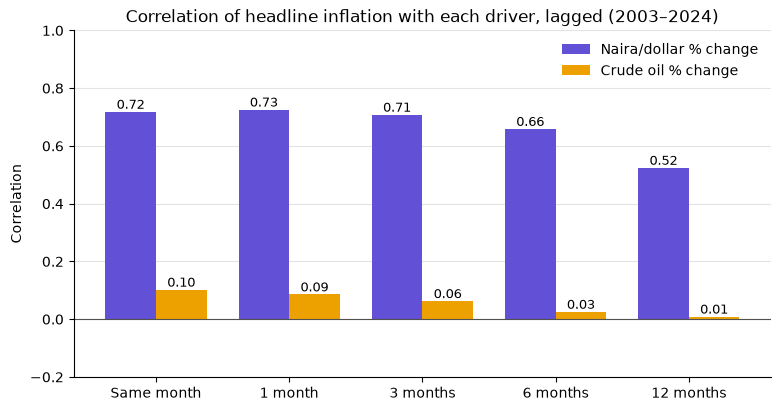

In [75]:
fig, ax = plt.subplots(figsize=(9, 4.5))
positions = range(len(lags))
bar_width = 0.38

fx_bars = ax.bar([p - bar_width / 2 for p in positions], lag_correlations["Naira fall vs Headline"],
                 width=bar_width, color=FX_COLOUR, label="Naira/dollar % change")
crude_bars = ax.bar([p + bar_width / 2 for p in positions], lag_correlations["Crude change vs Headline"],
                    width=bar_width, color=CRUDE_COLOUR, label="Crude oil % change")
ax.bar_label(fx_bars, fmt="%.2f", fontsize=9)
ax.bar_label(crude_bars, fmt="%.2f", fontsize=9)

ax.set_xticks(list(positions), ["Same month", "1 month", "3 months", "6 months", "12 months"])
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_ylim(-0.2, 1)
ax.set_title("Correlation of headline inflation with each driver, lagged (2003–2024)")
ax.set_ylabel("Correlation")
tidy_chart(ax)
ax.legend(loc="upper right", frameon=False)

fig.savefig("images/lag_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** - **The naira matters, a lot.** Headline inflation and the naira's year-on-year fall have a correlation of **0.72** in the same month, rising slightly to **0.73 at a 1-month lag**, the strongest. It's 0.71 at 3 months, 0.66 at 6 months, and fades to 0.52 at 12 months. Food (0.68) and core (0.63) follow the same pattern. The stacked chart shows it clearly: the 2016, 2020–21 and 2023–24 inflation waves each **began with a jump in the naira/dollar rate**. Since 2025, the naira has been *strengthening* (the dollar costs 10–15% fewer naira than a year earlier), which fits with inflation falling.
- **Crude oil barely matters, at any lag** (correlation 0.10 or less). One likely reason is that until mid-2023, petrol pump prices were fixed by the fuel subsidy, so world oil prices didn't reach Nigerian shoppers. Oil also pulls both ways for Nigeria: a higher oil price brings in more dollars (which supports the naira), but makes imported fuel dearer. Worth noting: in September 2026, crude was **67% more expensive** than a year earlier, and petrol is no longer subsidised, so this link may be stronger in future than in the past.
- **For modelling:** the lagged naira change (1 and 3 months) is our most promising extra feature. Crude oil looks weak, but we'll still test it rather than drop it on a hunch.

**A warning about correlation.** Correlation shows that two things move together. It doesn't prove that one *causes* the other. Both series
here change slowly, so this month's value is close to last month's, and that makes correlations at nearby lags look almost the same. The real
test is in Phase 6: does adding the lagged naira rate **actually lower the forecast error** on months the model hasn't seen?

## 5. Baselines

**Question:** How well can the *simplest possible* forecast do? Every model we build later has to beat this, or it isn't worth using.

A **baseline** is a forecast rule so simple it needs no learning. If a clever model can't beat "next month = this month", the cleverness is
adding nothing. In this section we:

1. Split the data by time into a **training set** and a **test set**
2. Learn the error measure we'll use for every model: **MAE**
3. Build three baselines and score them in two ways: **1 month ahead** and **12 months ahead**

### 5.1 Train/test split, by time

To judge a forecast fairly, we must test it on months it has **never seen**. So we hold back the **last 12 months** as the **test set**, and
build models only on the months before them (the **training set**).

**We never shuffle time-series data.** In many machine-learning projects, rows are shuffled randomly before splitting. Here that would be
cheating: the model would train on, say, March 2026 and then "forecast" February 2026, using knowledge of the future. Real forecasting
always goes forwards in time, so our split does too.

In [ ]:
TEST_MONTHS = 12

train = macro.iloc[:-TEST_MONTHS]  # every month except the last 12
test = macro.iloc[-TEST_MONTHS:]   # the last 12 months, hidden from the models

print(f"Training set: {train.index.min():%b %Y} to {train.index.max():%b %Y} ({len(train)} months)")
print(f"Test set:     {test.index.min():%b %Y} to {test.index.max():%b %Y} ({len(test)} months)")
print(f"Rebased months in the training set: {train['Rebased'].sum()}")

**Finding:** We train on **273 months** (January 2003 to September 2025) and test on **12 months** (October 2025 to September 2026).
The whole test year comes after the rebasing, but only **9 of the training months** (January–September 2025) do. Models will have very little
"new CPI" data to learn from, which is why we'll compare different ways of handling the break in Phases 6–7.

### 5.2 Measuring error: MAE

For each test month, the **error** is *actual − forecast*. Some errors are positive (we forecast too low) and some negative (too high).
If we simply averaged them, they'd cancel out, and a terrible forecast could look perfect. So we take the **absolute value** first,
dropping the minus sign, and then average. That's the **Mean Absolute Error (MAE)**:

> MAE = the average size of the miss

Our inflation rates are in %, so MAE is in **percentage points**. An MAE of 0.5 means "on average, the forecast was off by half a point",
for example forecasting 15.0% when the actual was 15.5%. Lower is better.

In [ ]:
def mae(actual, forecast):
    # Mean Absolute Error: the average size of the forecast miss, ignoring direction
    errors = actual - forecast
    return errors.abs().mean()


# A tiny example: misses of +1, -2 and +0.5 points -> average size (1 + 2 + 0.5) / 3 = 1.17
example_actual = pd.Series([15.0, 14.0, 13.5])
example_forecast = pd.Series([14.0, 16.0, 13.0])
print(f"Example MAE: {mae(example_actual, example_forecast):.2f} points")

### 5.3 Three baselines, forecasting 1 month ahead

Each test month, we forecast that month using only the months **before** it:

| Baseline | Rule | pandas |
|---|---|---|
| **Naive** | Next month = this month | `shift(1)` |
| **Moving average (3m)** | Next month = average of the last 3 months | `rolling(3).mean().shift(1)` |
| **Seasonal naive** | Next month = the same month a year earlier | `shift(12)` |

`shift(1)` moves the series one month later, so each month's row holds the *previous* month's value. That's how we make sure a forecast only
uses information **available at the time**. `rolling(3).mean()` averages each month with the two before it. We then `shift(1)` that too, so
the average never includes the month being forecast.

In [ ]:
def one_month_ahead_baselines(series):
    # Forecast each month using only the months before it
    return pd.DataFrame({
        "Naive": series.shift(1),                                  # last month's value
        "Moving average (3m)": series.rolling(3).mean().shift(1),  # average of the previous 3 months
        "Seasonal naive": series.shift(12),                        # same month, one year earlier
    })


headline_one_month = one_month_ahead_baselines(macro["Headline"]).loc[test.index]
headline_one_month.insert(0, "Actual", test["Headline"])
headline_one_month.round(2)

Now we score each baseline, for headline **and** food. We collect every score in a list called `scores`, and in Phase 8 we'll add
every other model's scores to the same list to compare them all.

In [ ]:
scores = []  # one entry per (model, target, horizon); we keep adding to this in later phases

for target in ["Headline", "Food"]:
    forecasts = one_month_ahead_baselines(macro[target]).loc[test.index]
    for model in forecasts.columns:
        scores.append({
            "Model": model,
            "Target": target,
            "Horizon": "1 month ahead",
            "MAE": mae(test[target], forecasts[model]),
        })

pd.DataFrame(scores).round(2)

### 5.4 The same baselines, forecasting 12 months ahead

Forecasting 1 month ahead is the easy case, because we always know last month's value. Our final forecast (Phase 9) looks **6–12 months**
ahead, so we also test that harder case. We stand at the **end of the training data (September 2025)**, and forecast all 12 test months at once,
without seeing any of them:

- **Naive:** every future month = September 2025's value (a flat line)
- **Moving average (3m):** every future month = the average of July–September 2025 (also flat)
- **Seasonal naive:** each future month = the same month a year earlier (October 2024 – September 2025, all already known)

In [ ]:
def twelve_months_ahead_baselines(train_series, future_dates):
    # Stand at the end of the training data and forecast every future month at once
    return pd.DataFrame({
        "Naive": train_series.iloc[-1],                         # last known value, repeated
        "Moving average (3m)": train_series.iloc[-3:].mean(),   # average of the last 3 known months, repeated
        "Seasonal naive": train_series.iloc[-12:].to_numpy(),   # the last 12 known months, in order
    }, index=future_dates)


for target in ["Headline", "Food"]:
    forecasts = twelve_months_ahead_baselines(train[target], test.index)
    for model in forecasts.columns:
        scores.append({
            "Model": model,
            "Target": target,
            "Horizon": "12 months ahead",
            "MAE": mae(test[target], forecasts[model]),
        })

# One row per model, one column per (horizon, target)
scores_table = pd.DataFrame(scores).pivot_table(index="Model", columns=["Horizon", "Target"], values="MAE")
scores_table.round(2)

### 5.5 Forecast vs actual

Each chart shows the actual headline rate (black) and each baseline's forecast for the test year. Left: 1 month ahead. Right: 12 months ahead.

Each model gets its own colour, and keeps it in every later chart, so you can always tell models apart.

In [ ]:
# One fixed colour per model, reused in every later forecast chart
MODEL_COLOURS = {
    "Naive": "#e87ba4",                # pink
    "Moving average (3m)": "#008300",  # green
    "Seasonal naive": "#9a9890",       # grey
}
ACTUAL_COLOUR = "#0b0b0b"              # near-black

In [ ]:
import matplotlib.dates as mdates  # tools for formatting dates on chart axes

history = macro.loc["2024-07":, "Headline"]
headline_twelve_months = twelve_months_ahead_baselines(train["Headline"], test.index)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
panels = [
    (axes[0], headline_one_month, "1 month ahead"),
    (axes[1], headline_twelve_months, "12 months ahead (from September 2025)"),
]

for ax, forecasts, title in panels:
    ax.plot(history.index, history, color=ACTUAL_COLOUR, linewidth=2, label="Actual")
    for model, colour in MODEL_COLOURS.items():
        ax.plot(forecasts.index, forecasts[model], color=colour, linewidth=2, linestyle="--", label=model)

    ax.set_ylim(0, 40)
    ax.axvline(test.index[0], color=ACTUAL_COLOUR, linewidth=0.8)
    ax.text(test.index[0], 3, " test period", fontsize=9)
    mark_rebasing(ax)
    ax.set_title(title)
    # One date label every 6 months, written like "Jan 2025"
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    tidy_chart(ax)

axes[0].set_ylabel("Headline inflation (%)")
# One shared legend underneath both charts
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Baseline forecasts vs actual headline inflation, test year Oct 2025 – Sep 2026")
fig.tight_layout(rect=[0, 0.07, 1, 1])  # leave room at the bottom for the legend

fig.savefig("images/baselines_headline.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:**

**1 month ahead, the naive forecast is excellent:** an MAE of just **0.67 points** for headline and **1.95** for food. Inflation moves slowly
from month to month, so "same as last month" is rarely far off. The 3-month moving average is **worse** (1.49 and 3.62): when inflation is
falling fast, as in late 2025, averaging in older and higher months makes the forecast lag behind.

**Seasonal naive is terrible** (MAE about 12–13 points). This teaches two things. First, a year-on-year rate *already* compares with last year,
so copying last year's rate is the wrong idea for this kind of data. Second, it copies October–December 2024 values (33.88%–34.80%), which were
measured on the **old CPI basket**. That's the rebasing break hurting a forecast directly.

**12 months ahead is much harder.** Naive's MAE jumps to **5.15 points** for headline: it kept forecasting September 2025's 20.98% while
inflation fell to about 15%. For food it's 4.63, but partly by luck: food dropped to 8.89% and then climbed back near its starting point,
so a flat line ended up close again by the end.

**The scores to beat:**

| | 1 month ahead | 12 months ahead |
|---|---|---|
| Headline | **0.67** | **5.15** |
| Food | **1.95** | **4.63** |

Beating 0.67 at 1 month ahead will be hard. The 12-month horizon is where a model has room to add real value.